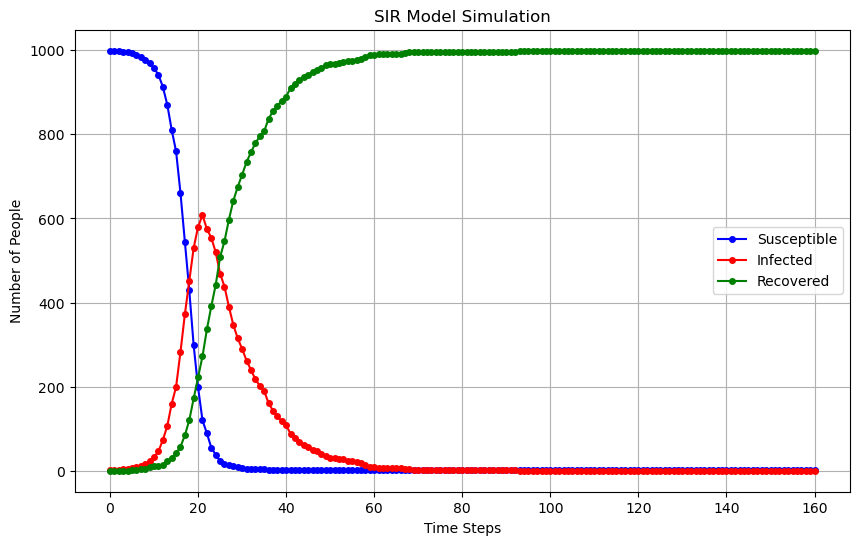

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import random

# 定义SIR模型类
class SIRModel:
    def __init__(self, N, beta, mu, initial_infected, initial_recovered):
        self.N = N  # 总人口
        self.beta = beta  # 感染率
        self.mu = mu  # 恢复率
        
        # 初始化SIR状态
        self.S = N - initial_infected - initial_recovered
        self.I = initial_infected
        self.R = initial_recovered
        
        self.S_history = [self.S]
        self.I_history = [self.I]
        self.R_history = [self.R]
        
    def step(self):
        new_infected = 0
        new_recovered = 0
        
        # 感染过程
        for _ in range(self.I):
            if random.random() < self.beta * self.S / self.N:
                new_infected += 1
        
        # 恢复过程
        for _ in range(self.I):
            if random.random() < self.mu:
                new_recovered += 1
        
        self.S = max(self.S - new_infected, 0)
        self.I = max(self.I + new_infected - new_recovered, 0)
        self.R = min(self.R + new_recovered, self.N)
        
        self.S_history.append(self.S)
        self.I_history.append(self.I)
        self.R_history.append(self.R)
        
    def run(self, steps):
        for _ in range(steps):
            self.step()

# 设置参数
N = 1000  # 总人口
beta = 0.6  # 感染率
mu = 0.1  # 恢复率
initial_infected = 1
initial_recovered = 0
steps = 160

# 初始化模型并运行
model = SIRModel(N, beta, mu, initial_infected, initial_recovered)
model.run(steps)

# 绘制结果
plt.figure(figsize=(10, 6))
plt.plot(model.S_history, 'bo-', label='Susceptible', markersize=4)
plt.plot(model.I_history, 'ro-', label='Infected', markersize=4)
plt.plot(model.R_history, 'go-', label='Recovered', markersize=4)
plt.xlabel('Time Steps')
plt.ylabel('Number of People')
plt.title('SIR Model Simulation')
plt.legend()
plt.grid(True)
plt.show()


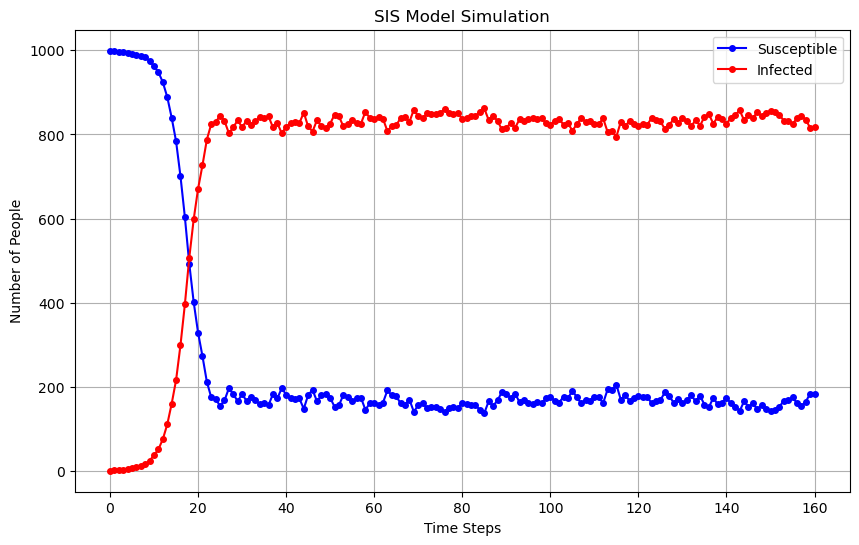

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import random

# 定义SIS模型类
class SISModel:
    def __init__(self, N, beta, mu, initial_infected):
        self.N = N  # 总人口
        self.beta = beta  # 感染率
        self.mu = mu  # 恢复率
        
        # 初始化SIS状态
        self.S = N - initial_infected
        self.I = initial_infected
        
        self.S_history = [self.S]
        self.I_history = [self.I]
        
    def step(self):
        new_infected = 0
        new_recovered = 0
        
        # 感染过程
        for _ in range(self.I):
            if random.random() < self.beta * self.S / self.N:
                new_infected += 1
        
        # 恢复过程
        for _ in range(self.I):
            if random.random() < self.mu:
                new_recovered += 1
        
        self.S = max(self.S - new_infected + new_recovered, 0)
        self.I = max(self.I + new_infected - new_recovered, 0)
        
        self.S_history.append(self.S)
        self.I_history.append(self.I)
        
    def run(self, steps):
        for _ in range(steps):
            self.step()

# 设置参数
N = 1000  # 总人口
beta = 0.6  # 感染率
mu = 0.1  # 恢复率
initial_infected = 1
steps = 160

# 初始化模型并运行
model = SISModel(N, beta, mu, initial_infected)
model.run(steps)

# 绘制结果
plt.figure(figsize=(10, 6))
plt.plot(model.S_history, 'bo-', label='Susceptible', markersize=4)
plt.plot(model.I_history, 'ro-', label='Infected', markersize=4)
plt.xlabel('Time Steps')
plt.ylabel('Number of People')
plt.title('SIS Model Simulation')
plt.legend()
plt.grid(True)
plt.show()


C:\Users\25369\AppData\Local\Temp\ipykernel_24960\2806269898.py:11: DeprecationWarning: Sampling from a set deprecated
since Python 3.9 and will be removed in a subsequent version.
  self.I = set(random.sample(self.S, initial_infected))


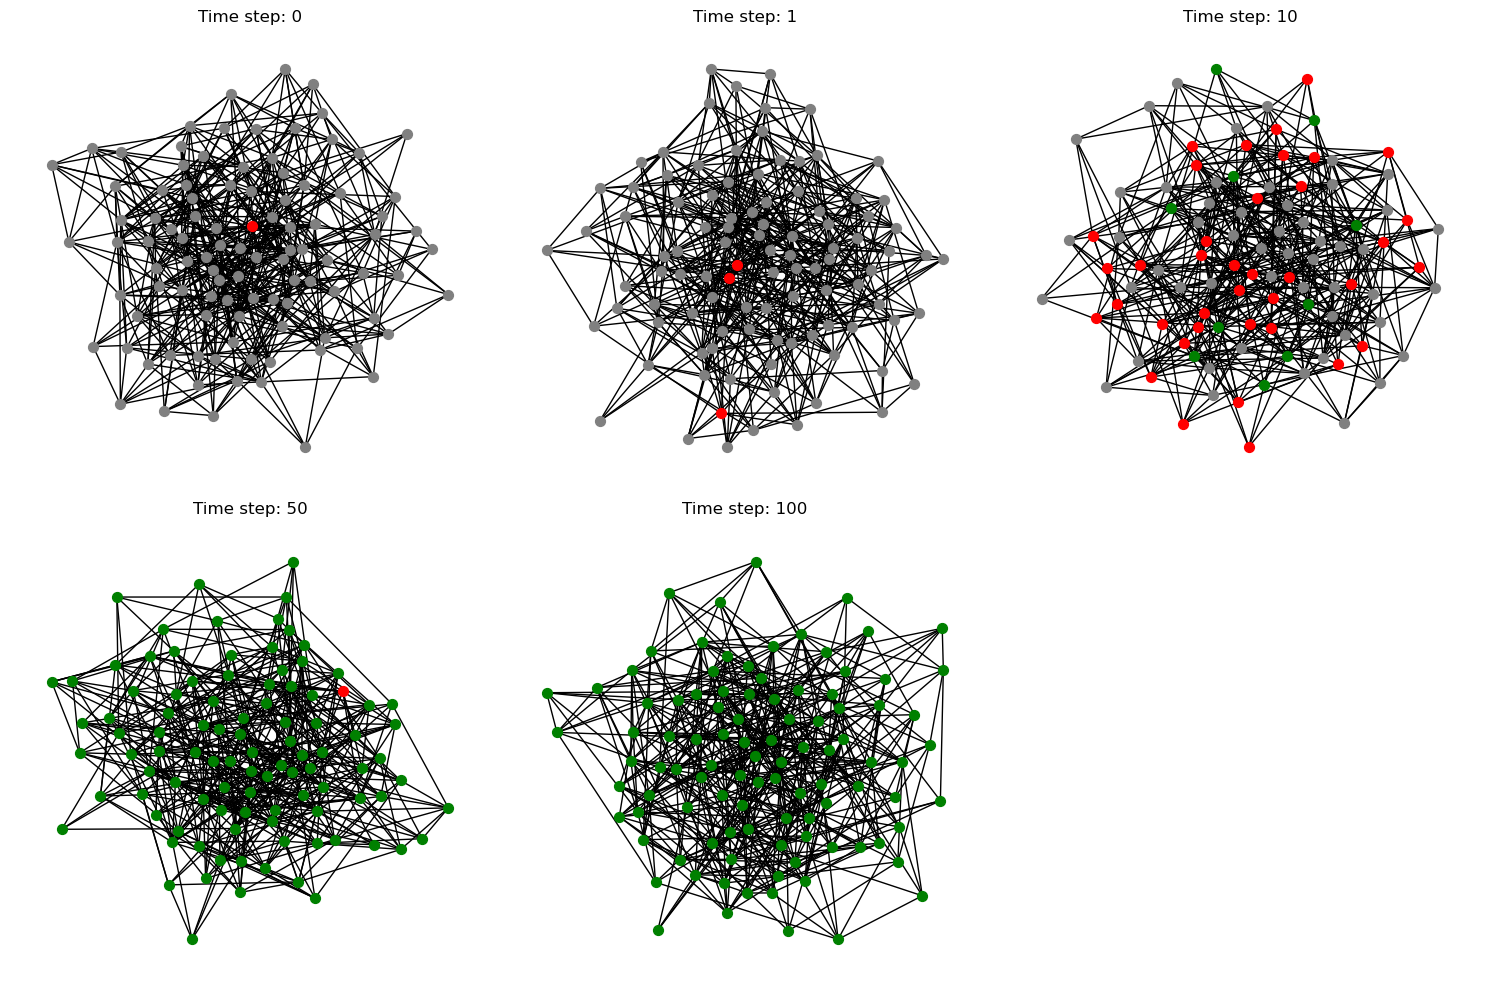

In [19]:
import networkx as nx
import matplotlib.pyplot as plt
import random

class SIR:
    def __init__(self, G, beta, mu, initial_infected):
        self.G = G
        self.beta = beta
        self.mu = mu
        self.S = set(G.nodes)
        self.I = set(random.sample(self.S, initial_infected))
        self.R = set()
        self.S -= self.I

    def step(self):
        new_infections = set()
        new_recoveries = set()
        
        # 感染过程
        for node in self.I:
            for neighbor in self.G.neighbors(node):
                if neighbor in self.S and random.random() < self.beta:
                    new_infections.add(neighbor)

        # 恢复过程
        for node in self.I:
            if random.random() < self.mu:
                new_recoveries.add(node)

        # 更新状态
        self.S -= new_infections
        self.I |= new_infections
        self.I -= new_recoveries
        self.R |= new_recoveries

    def run(self, steps):
        snapshots = []
        for _ in range(steps):
            self.step()
            snapshots.append((set(self.S), set(self.I), set(self.R)))
        return snapshots

def draw_graph(G, S, I, R, ax, title):
    pos = nx.spring_layout(G)
    nx.draw_networkx_nodes(G, pos, nodelist=S, node_color='grey', node_size=50, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=I, node_color='red', node_size=50, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=R, node_color='green', node_size=50, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax)
    ax.set_title(title)
    ax.axis('off')

# 参数设置
N = 100  # 总人口
beta = 0.1  # 感染率
mu = 0.1  # 恢复率
initial_infected = 1  # 初始感染人数
steps = 200  # 模拟时间步数

# 初始化图
G = nx.erdos_renyi_graph(N, 0.1)

# 初始化SIR模型
sir = SIR(G, beta, mu, initial_infected)

# 运行模型并获取每个时间步的快照
snapshots = sir.run(steps)

# 可视化结果
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
times = [0, 1, 10, 50, 100, 200]
for ax, t in zip(axes.flatten(), times):
    if t < len(snapshots):
        S, I, R = snapshots[t]
        draw_graph(G, S, I, R, ax, f'Time step: {t}')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()


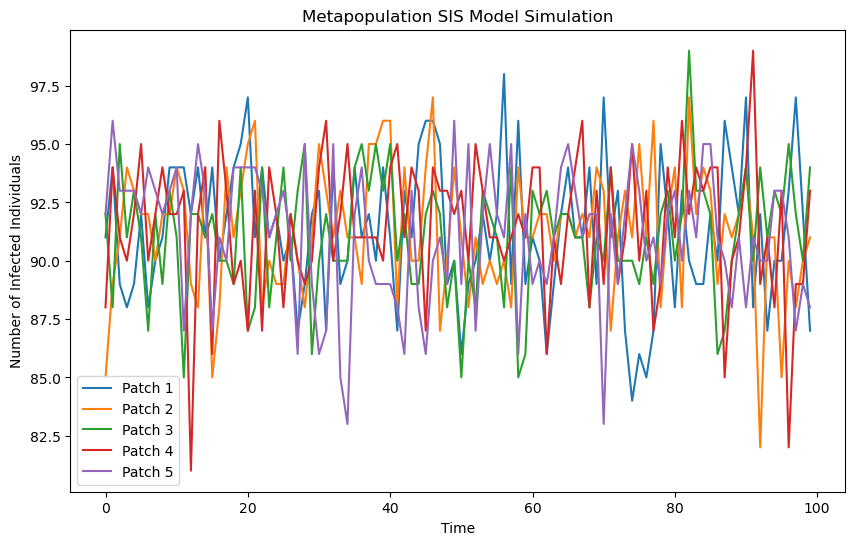

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 参数设置
num_patches = 5  # 子群体数量
population_per_patch = 100  # 每个子群体的个体数量
infection_rate = 0.05  # 感染率
recovery_rate = 0.01  # 恢复率
migration_rate = 0.1  # 迁移率
timesteps = 100  # 时间步长
initial_infected = 10  # 初始感染个体数量

# 初始化子群体状态
patches = np.zeros((num_patches, population_per_patch))
for i in range(num_patches):
    infected_indices = np.random.choice(population_per_patch, initial_infected, replace=False)
    patches[i, infected_indices] = 1

# 存储结果
infection_history = np.zeros((timesteps, num_patches))

# Monte Carlo 模拟
for t in range(timesteps):
    for i in range(num_patches):
        # 当前子群体状态
        current_patch = patches[i]
        
        # 感染过程
        for j in range(population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < infection_rate * np.sum(current_patch):
                current_patch[j] = 1
                
        # 恢复过程
        for j in range(population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < recovery_rate:
                current_patch[j] = 0
        
        # 迁移过程
        for j in range(population_per_patch):
            if np.random.rand() < migration_rate:
                target_patch = np.random.randint(num_patches)
                if target_patch != i:
                    patches[target_patch][np.random.randint(population_per_patch)] = current_patch[j]
                    current_patch[j] = 0
        
        # 更新子群体状态
        patches[i] = current_patch
        infection_history[t, i] = np.sum(current_patch)

# 可视化结果
plt.figure(figsize=(10, 6))
for i in range(num_patches):
    plt.plot(infection_history[:, i], label=f'Patch {i+1}')
plt.xlabel('Time')
plt.ylabel('Number of Infected Individuals')
plt.legend()
plt.title('Metapopulation SIS Model Simulation')
plt.show()


SIS Monte Calor metapopulation-Github

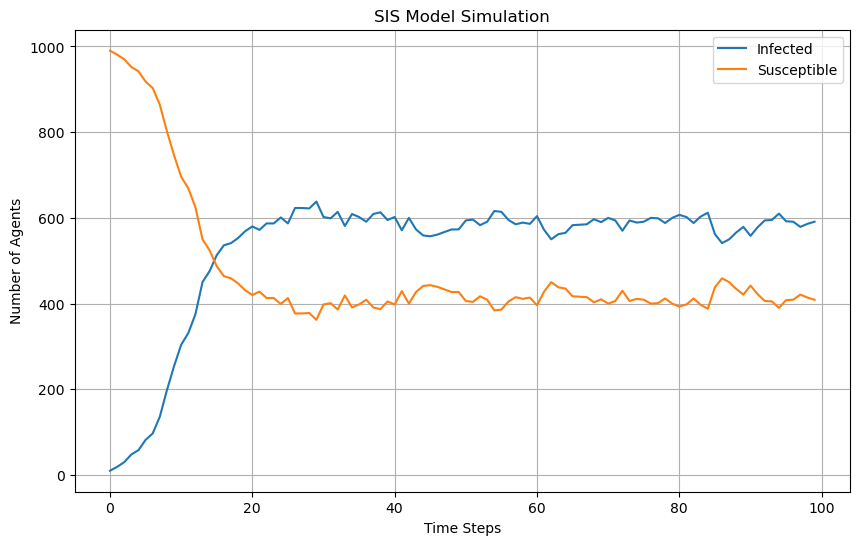

In [3]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from numpy import random as rnd
from enum import Enum, auto


class Agent:
    def __init__(self):
        self.state = HealthState.SUSCEPTIBLE
        self.next_state = HealthState.SUSCEPTIBLE
        self.location = None
        self.next_location = None


class HealthState(Enum):
    SUSCEPTIBLE = auto()
    INFECTED = auto()


class Simulation:
    def __init__(self, num_agents=1000, num_islands=20, num_initial_infected=1, average_degree=8, beta=0.833, gamma=0.33, migration_rate=0.2):
        self.num_agents = num_agents
        self.num_islands = num_islands
        self.num_initial_infected = num_initial_infected
        self.beta = beta
        self.gamma = gamma
        self.migration_rate = migration_rate

        self.agents = [Agent() for _ in range(num_agents)]
        self.topology = nx.barabasi_albert_graph(num_islands, average_degree // 2)

    def _initialize_agents(self):
        # 随机选择初始感染者
        initial_infected = rnd.choice(self.agents, size=self.num_initial_infected, replace=False)
        for agent in initial_infected:
            agent.state = HealthState.INFECTED
            agent.next_state = HealthState.INFECTED

        # 将每个岛屿分配相同数量的代理
        num_agents_per_island = len(self.agents) // self.num_islands
        for island_id in range(self.num_islands):
            # 计算当前岛屿的起始索引-结束索引（不包括）
            for agent in self.agents[island_id*num_agents_per_island:(island_id+1)*num_agents_per_island]:
                agent.location = island_id
                agent.next_location = island_id

    def _update_state(self):
        rand_nums = rnd.random(len(self.agents))
        infection_probabilities = np.zeros(self.num_islands)
        migration_probabilities = np.zeros(self.num_islands)

        # 计算每个岛屿上的代理数量以及每个岛屿上感染代理的数量
        island_population = np.zeros(self.num_islands)
        infected_count = np.zeros(self.num_islands)

        for agent in self.agents:
            island_population[agent.location] += 1
            if agent.state == HealthState.INFECTED:
                infected_count[agent.location] += 1

        infection_probabilities = self.beta * (infected_count / island_population)
        migration_probabilities = self.migration_rate * (infected_count / island_population)

        for i, agent in enumerate(self.agents):
            if agent.state == HealthState.SUSCEPTIBLE:
                if rand_nums[i] < infection_probabilities[agent.location]:
                    agent.next_state = HealthState.INFECTED
                if rand_nums[i] < migration_probabilities[agent.location]:
                    neighbors = list(self.topology.neighbors(agent.location))
                    if neighbors:
                        agent.next_location = rnd.choice(neighbors)
            elif agent.state == HealthState.INFECTED and rand_nums[i] < self.gamma:
                agent.next_state = HealthState.SUSCEPTIBLE
            else:
                agent.next_state = agent.state
                agent.next_location = agent.location

        for agent in self.agents:
            agent.state = agent.next_state
            agent.location = agent.next_location

    def _run_simulation(self):
        time_steps = 100
        infected_history = []
        susceptible_history = []

        for _ in range(time_steps):
            infected_count = sum(agent.state == HealthState.INFECTED for agent in self.agents)
            susceptible_count = sum(agent.state == HealthState.SUSCEPTIBLE for agent in self.agents)
            
            infected_history.append(infected_count)
            susceptible_history.append(susceptible_count)

            self._update_state()

        return infected_history, susceptible_history

    def run(self):
        self._initialize_agents()
        infected_history, susceptible_history = self._run_simulation()
        self._plot_results(infected_history, susceptible_history)

    def _plot_results(self, infected_history, susceptible_history):
        plt.figure(figsize=(10, 6))
        plt.plot(infected_history, label='Infected')
        plt.plot(susceptible_history, label='Susceptible')
        plt.xlabel('Time Steps')
        plt.ylabel('Number of Agents')
        plt.title('SIS Model Simulation')
        plt.legend()
        plt.grid(True)
        plt.show()


# 参数配置
num_agents = 1000
num_islands = 20
average_degree = 8
num_initial_infected = 10
beta = 0.833
gamma = 0.33
migration_rate = 0.2

# 运行模拟
simulation = Simulation(
    num_agents=num_agents,
    num_islands=num_islands,
    num_initial_infected=num_initial_infected,
    average_degree=average_degree,
    beta=beta,
    gamma=gamma,
    migration_rate=migration_rate
)
simulation.run()
